### Sesi 2 MLP
By: Tegar Arifin Prasetyo

## Library yang Digunakan

Pada bagian awal, beberapa library disiapkan karena masing-masing memiliki tugas yang berbeda selama praktikum. `pandas` digunakan untuk membaca dan mengolah data dalam bentuk tabel, sedangkan `NumPy` membantu perhitungan numerik. `Matplotlib` nantinya dipakai untuk menampilkan hubungan antarvariabel dan hasil prediksi dalam bentuk grafik. Untuk membangun jaringan saraf digunakan `TensorFlow`, sementara `train_test_split` dari Scikit-learn membantu membagi data menjadi data latihan dan data pengujian. `StandardScaler` juga diimpor, tetapi pada kode praktikum ini belum digunakan. Dengan menyiapkan library di awal, proses analisis dan pembuatan model dapat dilakukan menggunakan fungsi-fungsi yang sudah tersedia.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Menghubungkan Google Drive

Kode ini menghubungkan Google Colab dengan Google Drive. Langkah tersebut diperlukan apabila file dataset disimpan di Drive dan bukan di penyimpanan sementara Colab. Setelah proses mount berhasil, file dapat diakses melalui direktori `/content/drive`. Pada praktikum ini, perintah tersebut menjadi persiapan lingkungan kerja sebelum dataset digunakan. Jika file sudah berada langsung di folder kerja Colab, bagian penghubung Drive tidak selalu diperlukan.

In [5]:
dataset = pd.read_csv('advertising.csv')

dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


## Menginstal TensorFlow

Perintah `pip install tensorflow` digunakan untuk memasang TensorFlow pada lingkungan Python yang sedang digunakan. TensorFlow merupakan library utama untuk membangun dan melatih model neural network pada praktikum ini. Colab biasanya sudah menyediakan TensorFlow, tetapi perintah instalasi tetap dicantumkan agar library tersedia apabila lingkungan yang digunakan belum memilikinya. Setelah instalasi selesai, TensorFlow dapat dipanggil melalui perintah `import tensorflow as tf`.

In [6]:
!pip install tensorflow

## Menginstal Library Pendukung

Pada bagian ini dipasang tiga library pendukung, yaitu Pandas, Matplotlib, dan Scikit-learn. Pandas dibutuhkan untuk membaca file CSV, Matplotlib digunakan untuk membuat grafik, sedangkan Scikit-learn menyediakan fungsi pembagian dataset. Instalasi dilakukan sebelum kode analisis dijalankan supaya tidak muncul kesalahan karena library belum tersedia. Jika library tersebut sudah terpasang, perintah instalasi biasanya tidak perlu dijalankan kembali.

In [7]:
!pip install pandas matplotlib scikit-learn

## Memanggil Library

Library dipanggil menggunakan `import` agar fungsi-fungsinya dapat digunakan pada cell berikutnya. Penulisan `as pd`, `as np`, dan `as plt` merupakan pemberian nama singkat supaya pemanggilan fungsi lebih praktis. TensorFlow dipanggil sebagai `tf`, sedangkan `train_test_split` diambil langsung dari modul Scikit-learn. Pada notebook asli, beberapa import ditulis kembali setelah proses instalasi. Hal ini tidak mengubah cara kerja program, tetapi memastikan library sudah dapat dikenali oleh sesi Python.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Membaca Dataset Advertising

Perintah `pd.read_csv()` membaca file `advertising.csv` dan menyimpannya ke variabel `dataset`. File tersebut berisi data mengenai anggaran iklan pada tiga media, yaitu TV, Radio, dan Newspaper, serta nilai penjualan atau `Sales`. Setelah data dibaca, `dataset.head()` menampilkan lima baris pertama. Tampilan ini berguna untuk memastikan file berhasil dibuka sekaligus mengenali nama kolom dan bentuk data sebelum dilakukan pengolahan lebih lanjut.

In [9]:
# Load dataset
dataset = pd.read_csv('advertising.csv')

# Lihat beberapa baris dataset
dataset.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


## Melihat Ringkasan Statistik

Fungsi `describe()` digunakan untuk melihat gambaran umum isi dataset. Hasilnya mencakup jumlah data (`count`), nilai rata-rata (`mean`), standar deviasi (`std`), nilai terendah, kuartil, dan nilai tertinggi. Dari ringkasan ini, kita dapat mengetahui kisaran anggaran iklan dan penjualan serta membandingkan skala antar kolom. Informasi tersebut membantu memahami karakteristik dataset sebelum model dibuat. Nilai statistik yang muncul berasal dari data yang sedang dibaca, sehingga hasilnya akan mengikuti isi file CSV.

In [10]:
dataset.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Memeriksa Data Kosong

Perintah `dataset.isnull().sum()` memeriksa apakah terdapat nilai kosong pada setiap kolom. `isnull()` menandai sel yang tidak memiliki nilai, kemudian `sum()` menghitung jumlahnya untuk masing-masing kolom. Pemeriksaan ini penting karena data yang kosong dapat menyebabkan proses analisis atau pelatihan model tidak berjalan sebagaimana mestinya. Jika hasil untuk semua kolom adalah nol, berarti tidak ditemukan nilai kosong pada dataset yang diperiksa.

In [11]:
# Cek nilai null
dataset.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

## Memisahkan Fitur dan Target

Sebelum model dilatih, data perlu dipisahkan menjadi bagian input dan bagian yang ingin diprediksi. Baris `dataset.drop(['Sales'], axis=1)` mengambil seluruh kolom selain `Sales` dan menyimpannya ke variabel `X`. Dengan demikian, `X` berisi anggaran iklan TV, Radio, dan Newspaper. Sementara itu, `y` hanya berisi kolom `Sales` sebagai target prediksi. Fungsi `train_test_split()` kemudian membagi data dengan `test_size=0.2`, artinya 20 persen data digunakan untuk pengujian dan 80 persen untuk pelatihan. `random_state=42` membuat pembagian data tetap sama ketika kode dijalankan ulang.

In [12]:
# Split data menjadi training dan testing set
from sklearn.model_selection import train_test_split

X = dataset.drop(['Sales'], axis=1)
y = dataset['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Melihat Hubungan Anggaran Iklan dan Penjualan

Bagian ini membuat scatter plot untuk melihat sebaran data antara anggaran iklan dan nilai penjualan. Setiap titik menggambarkan satu baris data. Anggaran iklan ditempatkan pada sumbu horizontal, sedangkan `Sales` berada pada sumbu vertikal. Dengan melihat grafik TV, Radio, dan Newspaper, kita dapat memperoleh gambaran awal apakah kenaikan anggaran pada suatu media cenderung diikuti perubahan penjualan. Grafik ini masih berupa pengamatan visual dan belum menunjukkan bahwa suatu media iklan pasti menyebabkan peningkatan penjualan.

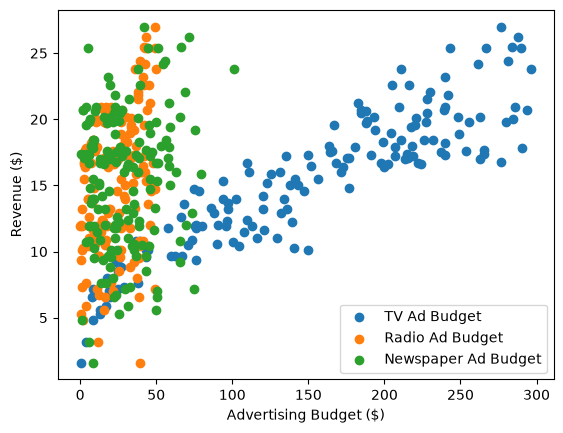

In [13]:
# Membuat plot dari dataset
plt.scatter(X_train['TV'], y_train, label='TV Ad Budget') # Changed column name to 'TV'
plt.scatter(X_train['Radio'], y_train, label='Radio Ad Budget') # Changed column name to 'Radio'
plt.scatter(X_train['Newspaper'], y_train, label='Newspaper Ad Budget') # Changed column name to 'Newspaper'
plt.xlabel('Advertising Budget ($)')
plt.ylabel('Revenue ($)')
plt.legend()
plt.show()

## Menyusun Model Multilayer Perceptron

Model dibuat menggunakan `Sequential`, yaitu susunan layer yang diproses secara berurutan. Layer pertama memiliki tiga input karena dataset menyediakan tiga fitur: TV, Radio, dan Newspaper. Tiga hidden layer menggunakan masing-masing 512, 512, dan 256 neuron dengan aktivasi ReLU. Layer terakhir hanya memiliki satu neuron karena model memprediksi satu nilai numerik, yaitu `Sales`. Model kemudian dikompilasi menggunakan optimizer Adam, fungsi loss Mean Squared Error (MSE), dan metrik Mean Absolute Error (MAE). MSE digunakan sebagai dasar perhitungan kesalahan saat bobot diperbarui, sedangkan MAE membantu membaca rata-rata besar kesalahan prediksi. `model.summary()` menampilkan susunan layer dan jumlah parameter yang dipelajari.

In [14]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

# Membangun model MLP
model = Sequential([
    Dense(512, input_shape=(3,), activation='relu'),  # Input layer
    Dense(512, activation='relu'),  # Hidden layer 1
    Dense(256, activation='relu'),  # Hidden layer 2
    Dense(1)  # Output layer (tidak perlu fungsi aktivasi karena ini masalah regresi)
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

c:\Users\msii\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 396,289 (1.51 MB)

 Trainable params: 396,289 (1.51 MB)

 Non-trainable params: 0 (0.00 B)

## Melatih Model

Sebelum training, kode membuat objek `EarlyStopping` yang memantau nilai `val_loss`. Tujuannya adalah menghentikan pelatihan apabila nilai validasi tidak membaik selama lima epoch berturut-turut. Namun, pada pemanggilan `model.fit()` callback tersebut belum dicantumkan melalui parameter `callbacks`, sehingga fitur EarlyStopping belum benar-benar digunakan. Model pada kode ini tetap dilatih selama 1400 epoch. Data `X_test` dan `y_test` diberikan sebagai `validation_data`, sehingga performa model juga diamati pada data validasi selama training. Perlu diperhatikan bahwa data testing idealnya disimpan khusus untuk evaluasi akhir, bukan digunakan berulang kali sebagai validasi.

In [15]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)
history = model.fit(X_train, y_train, epochs=1400, validation_data=(X_test, y_test))

Epoch 1/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - loss: 236.6085 - mae: 13.0230 - val_loss: 121.7108 - val_mae: 10.0509
Epoch 2/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 76.1875 - mae: 7.1405 - val_loss: 23.5301 - val_mae: 3.7548
Epoch 3/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 17.4458 - mae: 3.4926 - val_loss: 11.3226 - val_mae: 2.8265
Epoch 4/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 12.9779 - mae: 2.8029 - val_loss: 8.5734 - val_mae: 2.3916
Epoch 5/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 11.0802 - mae: 2.7616 - val_loss: 9.1139 - val_mae: 2.2635
Epoch 6/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 6.9235 - mae: 2.0725 - val_loss: 7.6938 - val_mae: 2.3418
Epoch 7/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 8.0620 - mae: 2.3218 - val_loss: 9.2928 - val_mae: 2.3368
Epoch 8/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 5.3244 - mae: 1.7950 - val_loss: 6.4786 - val_mae: 2.0819
Epoch 9/1400
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step -

## Mengukur Hasil pada Data Testing

Setelah proses training selesai, `model.evaluate(X_test, y_test)` digunakan untuk mengukur performa model pada data pengujian. Fungsi ini mengembalikan nilai loss dan MAE sesuai pengaturan saat model dikompilasi. Pada hasil praktikum, MAE tercatat sekitar 1,29. Artinya, rata-rata selisih absolut antara nilai penjualan sebenarnya dan nilai yang diprediksi model sekitar 1,29 satuan pada skala target `Sales`. Nilai MAE yang lebih kecil menunjukkan prediksi yang lebih dekat dengan nilai sebenarnya. MAE tidak boleh disebut sebagai akurasi 1,29 persen karena satuannya mengikuti target yang diprediksi.

In [16]:
test_loss, test_mae = model.evaluate(X_test, y_test)
print(f"Mean Absolute Error pada data pengujian: {test_mae}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 8.5047 - mae: 1.7073
Mean Absolute Error pada data pengujian: 1.7073490619659424


## Melihat Perkembangan Training

Grafik pada bagian ini menampilkan perubahan nilai loss dan MAE selama model dilatih. Garis training menunjukkan hasil pada data yang digunakan untuk memperbarui bobot, sedangkan garis validation menunjukkan hasil pada data validasi. Jika kedua nilai loss cenderung turun, hal tersebut menunjukkan model semakin baik dalam menyesuaikan prediksi. Namun, apabila training loss terus turun sementara validation loss justru meningkat, ada kemungkinan model terlalu menyesuaikan diri dengan data training atau mengalami overfitting. Karena itu, grafik membantu melihat proses belajar model, bukan hanya hasil akhirnya.

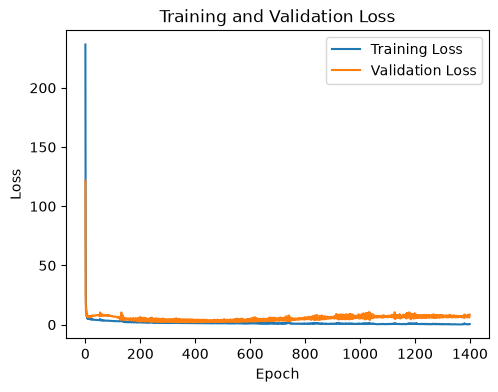

In [17]:
# Plot Loss dan MAE selama pelatihan
plt.figure(figsize=(12, 4))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()


## Membandingkan Prediksi dengan Data Aktual — TV

Pertama, `model.predict(X_test)` menghasilkan prediksi Sales untuk seluruh baris data pengujian. Hasil prediksi tersebut kemudian dibandingkan dengan nilai Sales sebenarnya melalui scatter plot. Titik biru menunjukkan data aktual, sedangkan titik merah menunjukkan hasil prediksi model. Sumbu horizontal pada grafik ini menggunakan anggaran TV agar sebaran prediksi dapat dilihat terhadap variabel tersebut. Model tetap menerima ketiga fitur sekaligus ketika membuat prediksi; grafik hanya memilih TV sebagai salah satu sudut pandang visual.

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


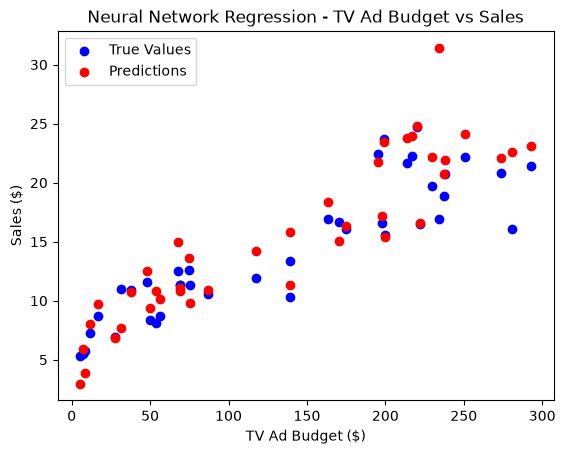

In [18]:
y_pred_test = model.predict(X_test)

plt.scatter(X_test['TV'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['TV'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('TV Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - TV Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

## Membandingkan Prediksi dengan Data Aktual — Radio

Grafik berikutnya menggunakan anggaran Radio pada sumbu horizontal. Tujuannya sama, yaitu memperlihatkan perbedaan antara nilai Sales aktual dan nilai yang diperkirakan model pada data testing. Dengan membandingkan posisi titik biru dan merah, kita dapat melihat secara kasar seberapa dekat hasil prediksi terhadap data sebenarnya. Perlu diingat bahwa model tidak hanya menggunakan anggaran Radio, tetapi juga TV dan Newspaper sebagai input.

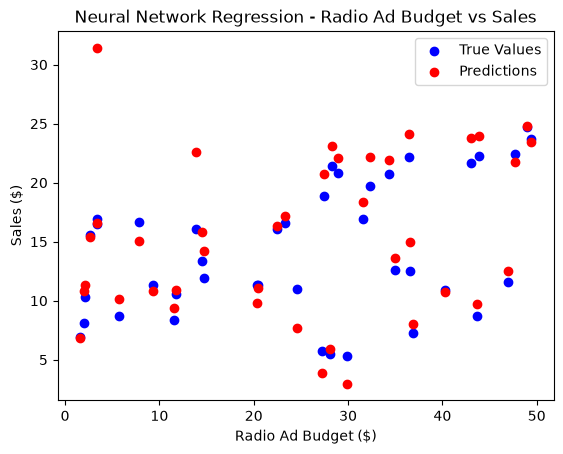

In [19]:
plt.scatter(X_test['Radio'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Radio'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Radio Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Radio Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()

## Membandingkan Prediksi dengan Data Aktual — Newspaper

Visualisasi terakhir menampilkan hubungan antara anggaran Newspaper dengan nilai Sales aktual dan prediksi. Grafik ini melengkapi dua grafik sebelumnya sehingga ketiga fitur input telah dilihat dari sisi visual. Jika titik prediksi berada dekat dengan titik aktual, berarti hasil model pada pengamatan tersebut relatif mendekati nilai sebenarnya. Meski demikian, penilaian utama tetap perlu melihat metrik evaluasi seperti MAE, karena grafik dua dimensi tidak menggambarkan seluruh kombinasi tiga fitur yang digunakan model.

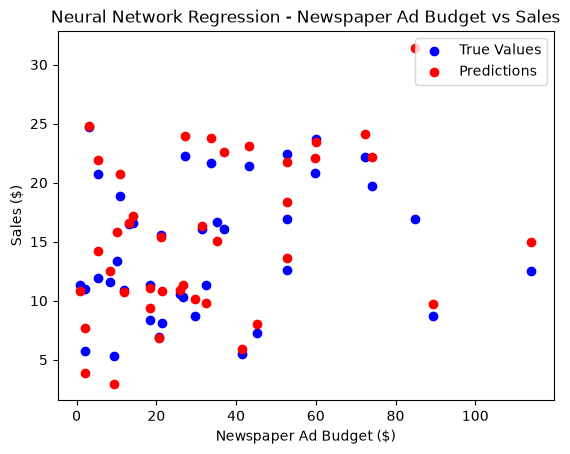

In [20]:
plt.scatter(X_test['Newspaper'], y_test, color='blue')

# Scatter plot of predictions (red)
plt.scatter(X_test['Newspaper'], y_pred_test, color='red')

# Set the axis labels and title
plt.xlabel('Newspaper Ad Budget ($)')
plt.ylabel('Sales ($)')
plt.title('Neural Network Regression - Newspaper Ad Budget vs Sales')

# Add a legend to the plot
plt.legend(['True Values', 'Predictions'])
plt.show()


**Tugas** <br>

Silahkan jelaskan secara rinci kode program dan hasilnya (hint: lihat slide sesi teori ada gambaran secara umum, di tugas ini kalian detailkan maksud dan tujuannya), dikumpulkan paling lambat Rabu, 11 November 2026 jam 23.59 di ecourse